# Week 2 · Technical Demonstration
## Python for creatives — images are numbers
*AI for Creativity · Level 6*

Every photo you have ever taken is secretly a **grid of numbers**. Today we learn to read and rewrite those numbers — and make glitch art.

> An AI model never "sees" a picture. It only ever sees these numbers. Understand them, and you understand what AI is working with.

**How to use this notebook**

- Works in **Google Colab** (open via *File → Upload notebook*) and in **Jupyter Notebook / JupyterLab** (Anaconda).
- Run a cell with **Shift + Enter**. Run cells **top to bottom** — later cells use things made in earlier ones.
- Grey text starting with `#` is a *comment*: a note for humans. Python ignores it.
- Broke something? *Runtime → Restart* (Colab) or *Kernel → Restart* (Jupyter) and run from the top. You cannot break the computer.

---
## Part 0 · Bug hunt (recap)
Three bugs from last week's labs. Can you spot them before running? Fixed versions are in the next cell.

```python
for i in range(4):
print("line")              # bug 1

print("Hello world")        # bug 2

colour = "#FF6B6B"
print(color)               # bug 3
```

In [1]:
for i in range(2):
    print("line")          # fix 1: indent lines inside a loop (IndentationError)

print("Hello world")       # fix 2: close the quotes (SyntaxError)

colour = "#FF6B6B"
print(colour)              # fix 3: spell the variable exactly the same (NameError)

line
line
Hello world
#FF6B6B


---
## Part 1 · Functions — reusable recipes
A function is a named recipe: **ingredients in** (parameters), **dish out** (`return`).

In [2]:
import random

def make_line(subject, verb, obj):
    """Join three words into one poem line."""
    return f"{subject} {verb} {obj}".capitalize()

print(make_line("the moon", "paints", "the sea"))

The moon paints the sea


In [3]:
def make_poem(words, n_lines=4):
    """Return n_lines random lines built from one word list."""
    return [make_line(random.choice(words), random.choice(["meets", "becomes", "forgets"]),
                      random.choice(words)) for _ in range(n_lines)]

print("\n".join(make_poem(["rain", "a lantern", "the old market", "salt"], n_lines=3)))

Rain forgets rain
The old market becomes rain
A lantern becomes the old market


---
## Part 2 · Decisions with `if / elif / else`

In [4]:
def words_for(mood):
    if mood == "calm":
        return ["still water", "soft linen", "morning fog"]
    elif mood == "angry":
        return ["broken glass", "a red siren", "thunder"]
    else:
        return ["a stranger", "the street", "an open door"]   # default for any other mood

for mood in ["calm", "angry", "curious"]:
    print(mood.upper(), "→", make_poem(words_for(mood), n_lines=1)[0])

CALM → Still water meets still water
ANGRY → A red siren becomes a red siren
CURIOUS → An open door forgets the street


---
## Part 3 · Libraries — borrowing superpowers
A **library** is code someone else wrote so you don't have to.

| Library | Superpower |
|---|---|
| `numpy` | Fast maths on huge grids of numbers |
| `PIL` (Pillow) | Opening and saving images |
| `matplotlib` | Drawing and showing images and charts |

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def load_image(path=None, max_side=600):
    """Load an image as a NumPy array (height x width x 3).
    No path? We use a sample photo of a cat from scikit-image."""
    if path:
        img = Image.open(path).convert("RGB")
    else:
        from skimage import data
        img = Image.fromarray(data.chelsea())
    img.thumbnail((max_side, max_side))          # shrink big photos so effects run fast
    return np.array(img)

def show(*images, titles=None):
    """Show one or more images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.show()

**Using your own image**
- *Colab:* click the folder icon on the left → upload → then use `load_image("yourfile.jpg")`.
- *Jupyter:* put the image in the same folder as this notebook → `load_image("yourfile.jpg")`.
- No image yet? `load_image()` gives you a sample cat photo.

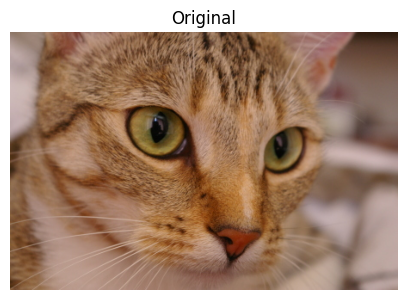

In [6]:
img = load_image()        # or load_image("your_photo.jpg")
show(img, titles=["Original"])

---
## Part 4 · An image is a grid of numbers

In [7]:
print("Shape (height, width, colour channels):", img.shape)
print("Type of number:", img.dtype, "→ whole numbers from 0 to 255")
print("Top-left pixel [R, G, B]:", img[0, 0])

Shape (height, width, colour channels): (300, 451, 3)
Type of number: uint8 → whole numbers from 0 to 255
Top-left pixel [R, G, B]: [143 120 104]


[[149 150 144 143 141 138]
 [148 147 138 140 140 135]
 [153 150 144 138 136 134]
 [160 155 151 148 141 134]
 [149 145 149 148 134 135]
 [149 151 145 143 137 137]]


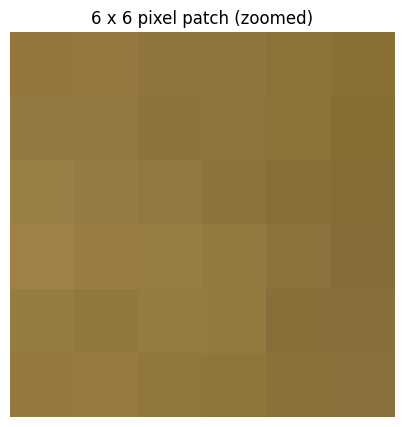

In [8]:
# Zoom in on a tiny 6 x 6 patch and print its red values
patch = img[100:106, 150:156]
print(patch[:, :, 0])
show(patch, titles=["6 x 6 pixel patch (zoomed)"])

---
## Part 5 · Rewriting the numbers = image effects

In [9]:
def invert(img):
    return 255 - img

def swap_channels(img, order=(2, 0, 1)):
    return img[:, :, list(order)]

def greyscale(img):
    grey = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
    return grey.astype(np.uint8)

def add_noise(img, amount=40):
    noise = np.random.randint(-amount, amount + 1, img.shape)
    return np.clip(img.astype(int) + noise, 0, 255).astype(np.uint8)

def row_shift_glitch(img, strength=40, band_height=12):
    out = img.copy()
    for top in range(0, img.shape[0], band_height):
        shift = np.random.randint(-strength, strength + 1)
        out[top:top + band_height] = np.roll(out[top:top + band_height], shift, axis=1)
    return out

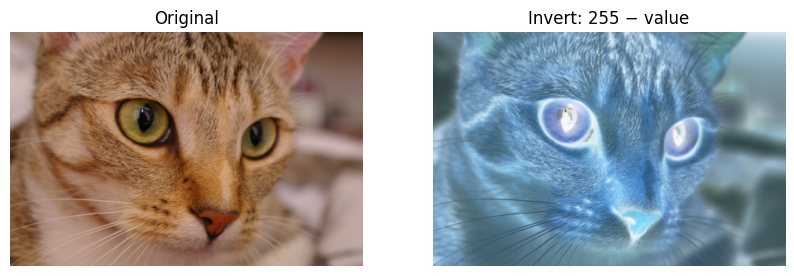

In [10]:
show(img, invert(img), titles=["Original", "Invert: 255 − value"])

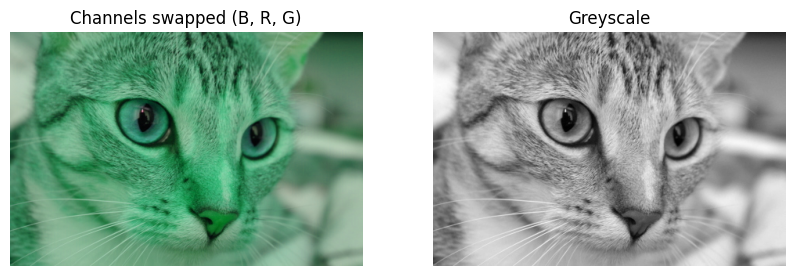

In [11]:
show(swap_channels(img), greyscale(img), titles=["Channels swapped (B, R, G)", "Greyscale"])

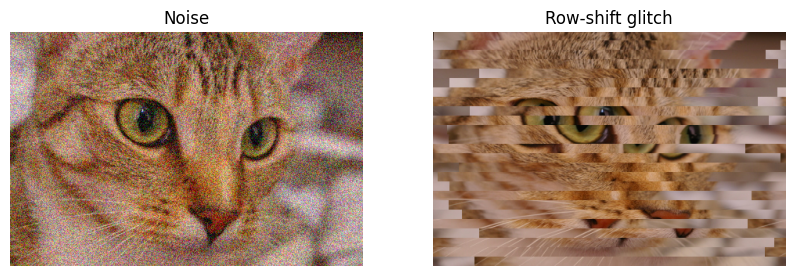

In [12]:
show(add_noise(img, 60), row_shift_glitch(img, strength=60), titles=["Noise", "Row-shift glitch"])

### Pixel sorting — a classic glitch-art technique
Sort the pixels in each row by brightness. Artists such as Kim Asendorf made this famous.

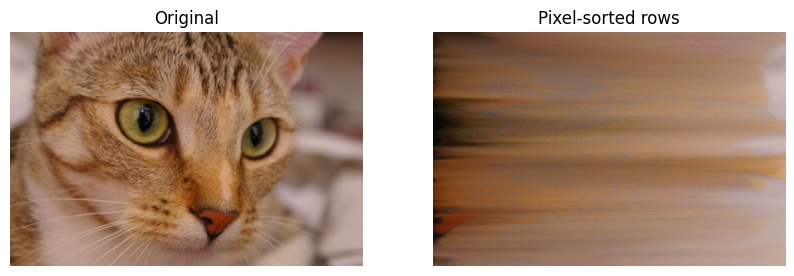

In [13]:
def pixel_sort(img, every_nth_row=1):
    out = img.copy()
    brightness = img.sum(axis=2)
    for y in range(0, img.shape[0], every_nth_row):
        order = np.argsort(brightness[y])
        out[y] = img[y, order]
    return out

show(img, pixel_sort(img), titles=["Original", "Pixel-sorted rows"])

### Stacking effects = your own filter

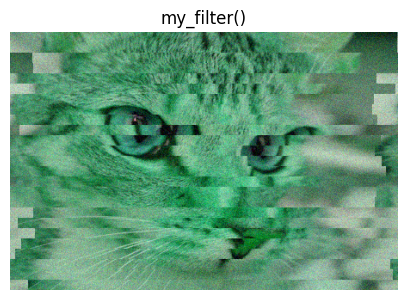

In [14]:
def my_filter(img):
    return row_shift_glitch(swap_channels(add_noise(img, 25)), strength=30)

result = my_filter(img)
show(result, titles=["my_filter()"])
Image.fromarray(result).save("glitch_01.png")

---
## Bridge to AI 🤖
When we train an image classifier in Week 5, the model receives exactly these arrays — millions of numbers from 0 to 255. Everything a model "knows" about cats, fabrics or painting styles is learned from patterns in these numbers.

**One-line reflection:** *If a model only sees numbers, what might it miss that a human sees?*